In [5]:
from brian2 import *

# Simulation parameters
duration = 100*ms

# HH equations
eqs = '''
dv/dt = (I_inj - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(mV**-1)*(v + 40*mV)/(1 - exp(-(v + 40*mV)/(10*mV))) /ms : Hz
betam = 4*exp(-(v + 65*mV)/(18*mV)) /ms : Hz
alphah = 0.07*exp(-(v + 65*mV)/(20*mV)) /ms : Hz
betah = 1/(1 + exp(-(v + 35*mV)/(10*mV))) /ms : Hz
alphan = 0.01*(mV**-1)*(v + 55*mV)/(1 - exp(-(v + 55*mV)/(10*mV))) /ms : Hz
betan = 0.125*exp(-(v + 65*mV)/(80*mV)) /ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2  # neuron surface area


# Create two populations
N1 = 5  # excitatory neurons
N2 = 5  # inhibitory neurons

P_exc = NeuronGroup(N1, eqs, method='exponential_euler', threshold='v > -20*mV', reset='v = -65*mV')
P_inh = NeuronGroup(N2, eqs, method='exponential_euler', threshold='v > -20*mV', reset='v = -65*mV')

# Initial conditions
P_exc.v = -65*mV
P_exc.m = 0.05
P_exc.h = 0.6
P_exc.n = 0.32
P_exc.I_inj = 0*nA

P_inh.v = -65*mV
P_inh.m = 0.05
P_inh.h = 0.6
P_inh.n = 0.32
P_inh.I_inj = 0*nA


# Example stimulation to one neuron in each group
P_exc.I_inj[0] = 10*nA
P_inh.I_inj[0] = 5*nA


# Synapses (example: all-to-all excitatory -> inhibitory)
S = Synapses(P_exc, P_inh, on_pre='v_post += 2*mV')  # simple synaptic effect
S.connect()

# Monitors
M_exc = StateMonitor(P_exc, 'v', record=True)
M_inh = StateMonitor(P_inh, 'v', record=True)

# Run
run(duration)

# Plot
import matplotlib.pyplot as plt

figure(figsize=(10, 4))
subplot(121)
for i in range(N1):
    plot(M_exc.t/ms, M_exc.v[i]/mV, label=f'Exc {i}')
xlabel('Time (ms)')
ylabel('v (mV)')
legend()

subplot(122)
for i in range(N2):
    plot(M_inh.t/ms, M_inh.v[i]/mV, label=f'Inh {i}')
xlabel('Time (ms)')
ylabel('v (mV)')
legend()
show()


BrianObjectException: Error encountered with object named 'neurongroup_1'.
Object was created here (most recent call only, full details in debug log):
  File '/tmp/ipykernel_1375/3026658999.py', line 36, in <module>
    P_exc = NeuronGroup(N1, eqs, method='exponential_euler', threshold='v > -20*mV', reset='v = -65*mV')

An error occurred when preparing an object. (See above for original error message and traceback.)

In [7]:
!pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 5.8 MB/s eta 0:00:00a 0:00:01


Spike counts before plasticity: <spikemonitor_1.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>


WARNING    'w' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value 0.7500000000000001. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Plasticity step 0.0 ms
Plasticity step 1000.0 ms
Plasticity step 2000.0 ms
Plasticity step 3000.0 ms
Plasticity step 4000.0 ms
Plasticity step 5000.0 ms
Plasticity step 6000.0 ms
Plasticity step 7000.0 ms
Plasticity step 8000.0 ms
Plasticity step 9000.0 ms
Plasticity step 10000.0 ms
Plasticity step 11000.0 ms
Plasticity step 12000.0 ms
Plasticity step 13000.0 ms
Plasticity step 14000.0 ms
Plasticity step 15000.0 ms
Plasticity step 16000.0 ms
Plasticity step 17000.0 ms
Plasticity step 18000.0 ms
Plasticity step 19000.0 ms
Plasticity step 20000.0 ms
Plasticity step 21000.0 ms
Plasticity step 22000.0 ms
Plasticity step 23000.0 ms
Plasticity step 24000.0 ms
Plasticity step 25000.0 ms
Plasticity step 26000.0 ms
Plasticity step 27000.0 ms
Plasticity step 28000.0 ms
Plasticity step 29000.0 ms
Plasticity step 30000.0 ms
Plasticity step 31000.0 ms
Plasticity step 32000.0 ms
Plasticity step 33000.0 ms
Plasticity step 34000.0 ms
Plasticity step 35000.0 ms
Plasticity step 36000.0 ms
Plasticity ste

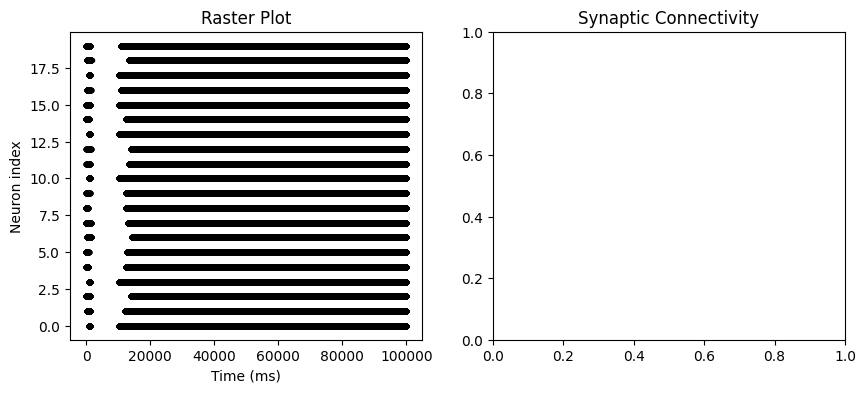

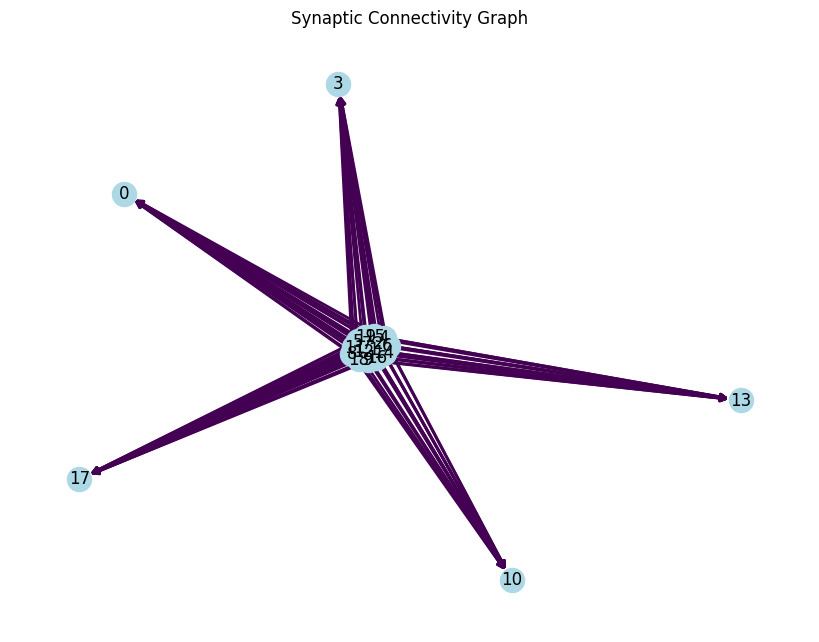

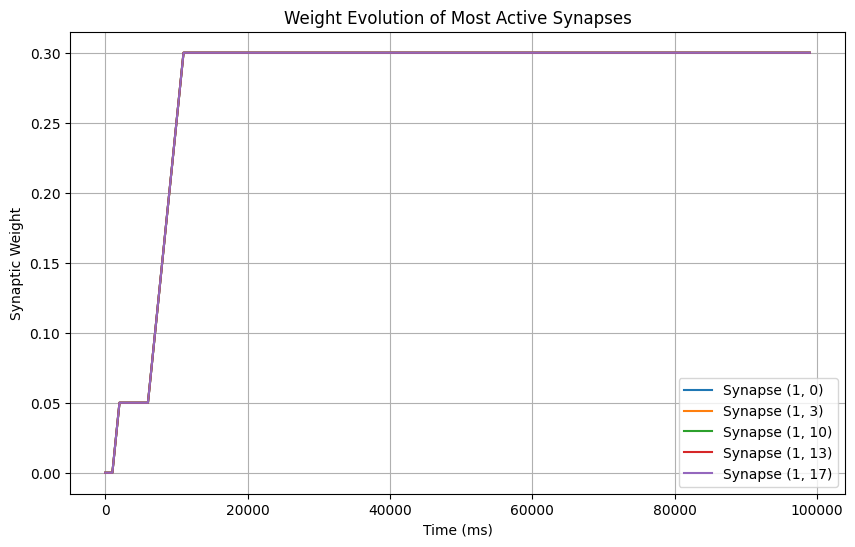

In [20]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 100*second
target_rate = 10*Hz
weight_trace = {}
times = []

# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to 15 random neurons
stim_indices = np.random.choice(N, size=15, replace=False)
P_input = PoissonGroup(15, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(15), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')

S_rec.connect(condition='i != j')
S_rec.w[:] = 0.0  # initial weights

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 100 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print("Plasticity step", defaultclock.t/ms, "ms")
    for u in underactive:
        for o in overactive:
            if o == u:
                continue  # skip self-connection
            S_rec.w[o, u] = clip(S_rec.w[o, u] + 0.05, 0, 1.0)

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# Network graph
print(f"Number of synapses: {len(S_rec.i[:])}")

plt.subplot(122)
plt.title("Synaptic Connectivity")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.title("Synaptic Connectivity Graph")
    plt.show()

def find_most_active_synapses(weight_trace):
    # Calculate the change in weight for each synapse
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)  # max change
    
    # Sort synapses by the largest change in weight
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    
    # Select top N active synapses to monitor (e.g., top 5)
    top_synapses = [synapse for synapse, _ in most_active[:5]]
    
    return top_synapses

top_synapses = find_most_active_synapses(weight_trace)

# Plot their weight evolution
plt.figure(figsize=(10, 6))

for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')

plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()
